# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhammad Dzaky Haidar | 5054251039 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_df = pd.read_csv("fashion-mnist_train.csv")
test_df  = pd.read_csv("fashion-mnist_test.csv")

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

Train shape: (60000, 785)
Test shape : (10000, 785)


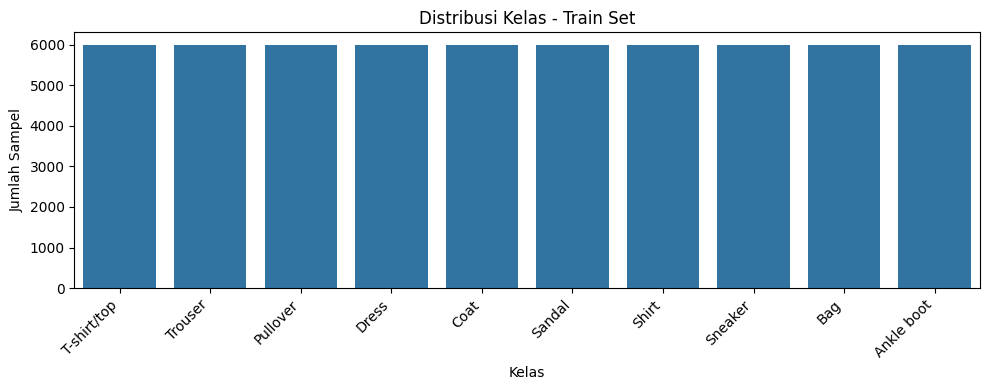

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

label_counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
sns.barplot(x=[class_names[i] for i in label_counts.index], y=label_counts.values)
plt.title("Distribusi Kelas - Train Set")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Sampel")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

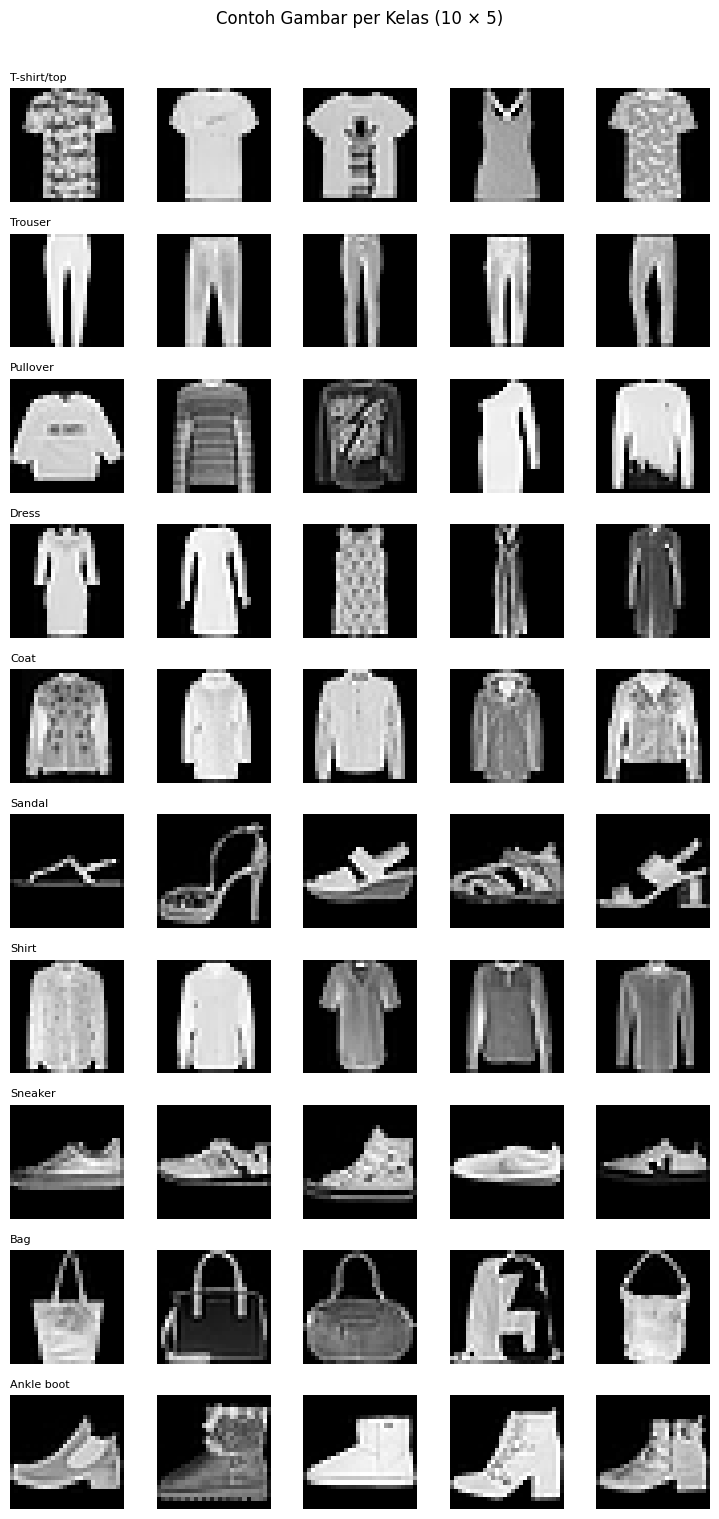

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

n_cols = 5
n_rows = 10
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.5, n_rows * 1.5))

pixel_cols = [c for c in train_df.columns if c != "label"]

for row, (label, name) in enumerate(class_names.items()):
    samples = train_df[train_df["label"] == label][pixel_cols].values[:n_cols]
    for col, pixels in enumerate(samples):
        ax = axes[row, col]
        ax.imshow(pixels.reshape(28, 28), cmap="gray")
        ax.axis("off")
        if col == 0:
            ax.set_title(name, fontsize=8, loc="left")

plt.suptitle("Contoh Gambar per Kelas (10 × 5)", y=1.01)
plt.tight_layout()
plt.show()

# Kelas yang visual mirip: Shirt vs T-shirt/top vs Pullover vs Coat (semua atasan bahu agak sulit dibedakan)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [5]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

pixel_cols = [c for c in train_df.columns if c != "label"]

X_train_full = train_df[pixel_cols].values  
y_train_full = train_df["label"].values      

X_test_raw = test_df[pixel_cols].values     
y_test_raw = test_df["label"].values    

print("X_train_full:", X_train_full.shape, "y_train_full:", y_train_full.shape)
print("X_test_raw  :", X_test_raw.shape,   "y_test_raw  :", y_test_raw.shape)

X_train_full: (60000, 784) y_train_full: (60000,)
X_test_raw  : (10000, 784) y_test_raw  : (10000,)


In [6]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full / 255.0
X_test_raw   = X_test_raw   / 255.0

In [7]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.1, random_state=42, stratify=y_train_full
)

print("X_train:", X_train.shape, "X_val:", X_val.shape)

X_train: (54000, 784) X_val: (6000, 784)


In [8]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

BATCH_SIZE = 64

def to_tensor_dataset(X, y):
    X_t = torch.tensor(X, dtype=torch.float32).reshape(-1, 1, 28, 28)
    y_t = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_t, y_t)

train_ds = to_tensor_dataset(X_train,   y_train)
val_ds   = to_tensor_dataset(X_val,     y_val)
test_ds  = to_tensor_dataset(X_test_raw, y_test_raw)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

Train batches: 844, Val batches: 94, Test batches: 157


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [9]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

ann = ANN().to(device)
print(ann)
print("Parameters:", sum(p.numel() for p in ann.parameters()))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 235146


In [10]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

EPOCHS = 15
LR     = 1e-3
criterion = nn.CrossEntropyLoss()

def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LR):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        # --- train ---
        model.train()
        total_loss, correct, total = 0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out  = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
            correct    += (out.argmax(1) == y).sum().item()
            total      += len(y)
        history["train_loss"].append(total_loss / total)
        history["train_acc"].append(correct / total)

        # --- val ---
        model.eval()
        v_loss, v_correct, v_total = 0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out  = model(x)
                loss = criterion(out, y)
                v_loss    += loss.item() * len(y)
                v_correct += (out.argmax(1) == y).sum().item()
                v_total   += len(y)
        history["val_loss"].append(v_loss / v_total)
        history["val_acc"].append(v_correct / v_total)

        print(f"Epoch {epoch:02d}/{epochs} | "
              f"Train Loss: {history['train_loss'][-1]:.4f} Acc: {history['train_acc'][-1]:.4f} | "
              f"Val Loss: {history['val_loss'][-1]:.4f} Acc: {history['val_acc'][-1]:.4f}")

    return history

ann_history = train_model(ann, train_loader, val_loader)

Epoch 01/15 | Train Loss: 0.5435 Acc: 0.8064 | Val Loss: 0.4469 Acc: 0.8360
Epoch 02/15 | Train Loss: 0.3833 Acc: 0.8589 | Val Loss: 0.3697 Acc: 0.8612
Epoch 03/15 | Train Loss: 0.3403 Acc: 0.8752 | Val Loss: 0.3614 Acc: 0.8692
Epoch 04/15 | Train Loss: 0.3180 Acc: 0.8836 | Val Loss: 0.3219 Acc: 0.8827
Epoch 05/15 | Train Loss: 0.2971 Acc: 0.8893 | Val Loss: 0.3361 Acc: 0.8750
Epoch 06/15 | Train Loss: 0.2825 Acc: 0.8949 | Val Loss: 0.3201 Acc: 0.8860
Epoch 07/15 | Train Loss: 0.2679 Acc: 0.8999 | Val Loss: 0.3159 Acc: 0.8872
Epoch 08/15 | Train Loss: 0.2567 Acc: 0.9038 | Val Loss: 0.3132 Acc: 0.8890
Epoch 09/15 | Train Loss: 0.2445 Acc: 0.9089 | Val Loss: 0.3199 Acc: 0.8890
Epoch 10/15 | Train Loss: 0.2339 Acc: 0.9111 | Val Loss: 0.3214 Acc: 0.8855
Epoch 11/15 | Train Loss: 0.2253 Acc: 0.9148 | Val Loss: 0.3333 Acc: 0.8868
Epoch 12/15 | Train Loss: 0.2171 Acc: 0.9175 | Val Loss: 0.3090 Acc: 0.8923
Epoch 13/15 | Train Loss: 0.2088 Acc: 0.9211 | Val Loss: 0.3343 Acc: 0.8858
Epoch 14/15 

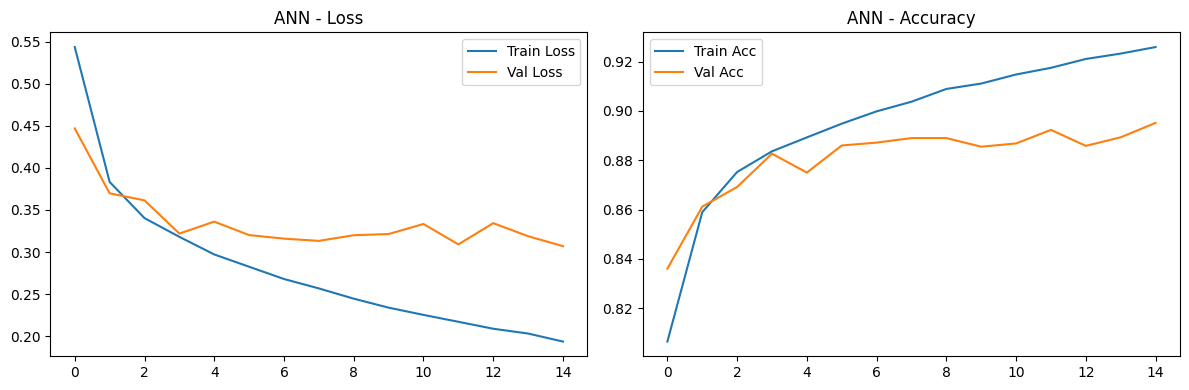

In [11]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_history(history, title="Learning Curve"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history["train_loss"], label="Train Loss")
    ax1.plot(history["val_loss"],   label="Val Loss")
    ax1.set_title(f"{title} - Loss"); ax1.legend()
    ax2.plot(history["train_acc"], label="Train Acc")
    ax2.plot(history["val_acc"],   label="Val Acc")
    ax2.set_title(f"{title} - Accuracy"); ax2.legend()
    plt.tight_layout(); plt.show()

plot_history(ann_history, "ANN")

In [12]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in loader:
            out = model(x.to(device))
            preds.append(out.argmax(dim=1).cpu().numpy())
    return np.concatenate(preds)

ann_preds = predict(ann, test_loader)
print("ANN preds shape:", ann_preds.shape)

ANN preds shape: (10000,)


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = SimpleCNN().to(device)
print(cnn)
print("Parameters:", sum(p.numel() for p in cnn.parameters()))
dummy = torch.zeros(1, 1, 28, 28).to(device)
print("Feature output shape:", cnn.features(dummy).shape)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 421642
Feature output shape: torch.Size([1, 64, 7, 7])


Epoch 01/15 | Train Loss: 0.4891 Acc: 0.8235 | Val Loss: 0.3533 Acc: 0.8753
Epoch 02/15 | Train Loss: 0.3146 Acc: 0.8866 | Val Loss: 0.3258 Acc: 0.8830
Epoch 03/15 | Train Loss: 0.2632 Acc: 0.9049 | Val Loss: 0.2738 Acc: 0.9047
Epoch 04/15 | Train Loss: 0.2317 Acc: 0.9148 | Val Loss: 0.2508 Acc: 0.9110
Epoch 05/15 | Train Loss: 0.2090 Acc: 0.9230 | Val Loss: 0.2598 Acc: 0.9038
Epoch 06/15 | Train Loss: 0.1904 Acc: 0.9293 | Val Loss: 0.2469 Acc: 0.9088
Epoch 07/15 | Train Loss: 0.1696 Acc: 0.9378 | Val Loss: 0.2359 Acc: 0.9128
Epoch 08/15 | Train Loss: 0.1529 Acc: 0.9433 | Val Loss: 0.2225 Acc: 0.9207
Epoch 09/15 | Train Loss: 0.1333 Acc: 0.9507 | Val Loss: 0.2429 Acc: 0.9158
Epoch 10/15 | Train Loss: 0.1192 Acc: 0.9561 | Val Loss: 0.2515 Acc: 0.9162
Epoch 11/15 | Train Loss: 0.1021 Acc: 0.9618 | Val Loss: 0.2629 Acc: 0.9193
Epoch 12/15 | Train Loss: 0.0898 Acc: 0.9673 | Val Loss: 0.2678 Acc: 0.9195
Epoch 13/15 | Train Loss: 0.0779 Acc: 0.9715 | Val Loss: 0.2855 Acc: 0.9185
Epoch 14/15 

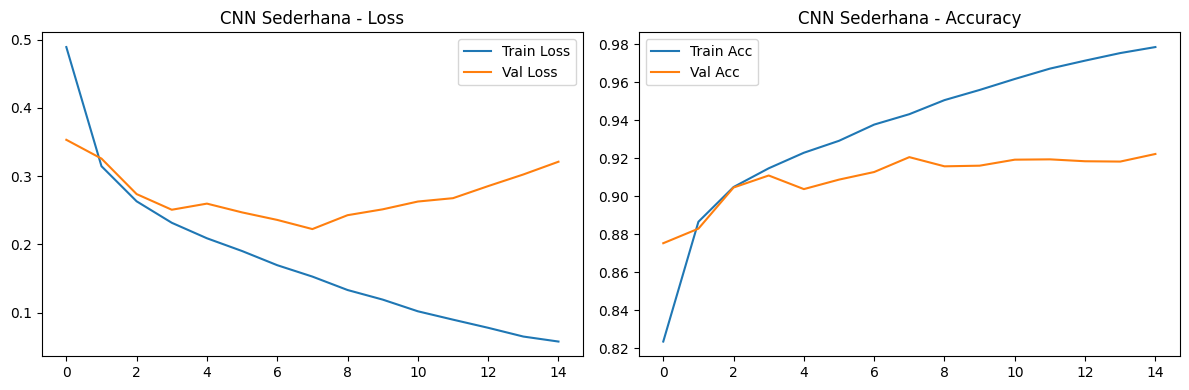

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

cnn_history = train_model(cnn, train_loader, val_loader)
plot_history(cnn_history, "CNN Sederhana")

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

cnn_preds = predict(cnn, test_loader)
print("CNN preds shape:", cnn_preds.shape)

CNN preds shape: (10000,)


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNNBN(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn_bn = CNNBN().to(device)
print(cnn_bn)
print("Parameters:", sum(p.numel() for p in cnn_bn.parameters()))

CNNBN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 421834


Epoch 01/15 | Train Loss: 0.5237 Acc: 0.8097 | Val Loss: 0.3317 Acc: 0.8795
Epoch 02/15 | Train Loss: 0.3706 Acc: 0.8678 | Val Loss: 0.2853 Acc: 0.8970
Epoch 03/15 | Train Loss: 0.3205 Acc: 0.8849 | Val Loss: 0.2715 Acc: 0.9030
Epoch 04/15 | Train Loss: 0.2909 Acc: 0.8952 | Val Loss: 0.2494 Acc: 0.9112
Epoch 05/15 | Train Loss: 0.2695 Acc: 0.9008 | Val Loss: 0.2434 Acc: 0.9123
Epoch 06/15 | Train Loss: 0.2502 Acc: 0.9094 | Val Loss: 0.2355 Acc: 0.9158
Epoch 07/15 | Train Loss: 0.2363 Acc: 0.9132 | Val Loss: 0.2304 Acc: 0.9188
Epoch 08/15 | Train Loss: 0.2220 Acc: 0.9194 | Val Loss: 0.2319 Acc: 0.9175
Epoch 09/15 | Train Loss: 0.2082 Acc: 0.9242 | Val Loss: 0.2290 Acc: 0.9220
Epoch 10/15 | Train Loss: 0.1985 Acc: 0.9276 | Val Loss: 0.2216 Acc: 0.9220
Epoch 11/15 | Train Loss: 0.1891 Acc: 0.9305 | Val Loss: 0.2303 Acc: 0.9218
Epoch 12/15 | Train Loss: 0.1784 Acc: 0.9342 | Val Loss: 0.2367 Acc: 0.9228
Epoch 13/15 | Train Loss: 0.1674 Acc: 0.9378 | Val Loss: 0.2330 Acc: 0.9232
Epoch 14/15 

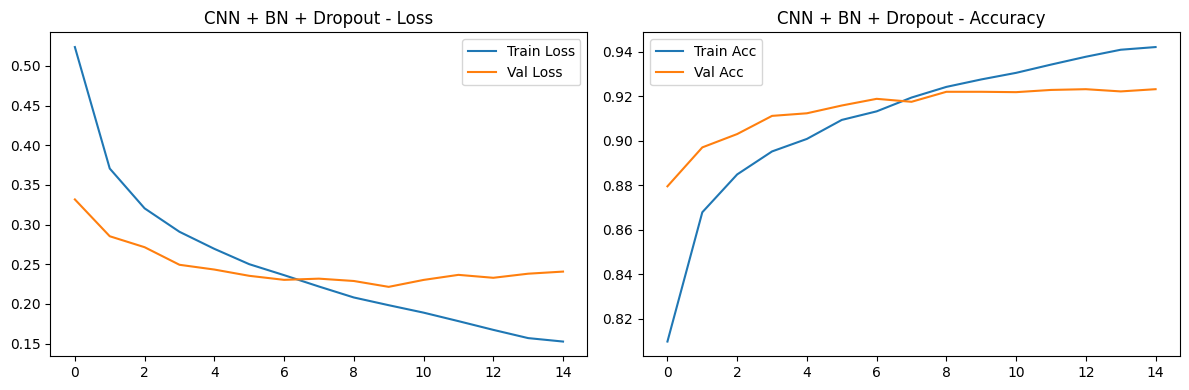

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

cnn_bn_history = train_model(cnn_bn, train_loader, val_loader)
plot_history(cnn_bn_history, "CNN + BN + Dropout")

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

cnn_bn_preds = predict(cnn_bn, test_loader)
print("CNN+BN preds shape:", cnn_bn_preds.shape)

CNN+BN preds shape: (10000,)


# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

y_true = y_test_raw

def metrics_row(name, model, preds):
    n_params = sum(p.numel() for p in model.parameters())
    return {
        "Model": name,
        "Params": n_params,
        "Accuracy":  round(accuracy_score(y_true, preds), 4),
        "Precision": round(precision_score(y_true, preds, average="macro", zero_division=0), 4),
        "Recall":    round(recall_score(y_true, preds, average="macro", zero_division=0), 4),
        "F1-Score":  round(f1_score(y_true, preds, average="macro", zero_division=0), 4),
    }

results = pd.DataFrame([
    metrics_row("ANN",              ann,    ann_preds),
    metrics_row("CNN Sederhana",    cnn,    cnn_preds),
    metrics_row("CNN + BN + Drop",  cnn_bn, cnn_bn_preds),
])
print(results.to_string(index=False))

          Model  Params  Accuracy  Precision  Recall  F1-Score
            ANN  235146    0.9000     0.9006  0.9000    0.8999
  CNN Sederhana  421642    0.9234     0.9241  0.9234    0.9235
CNN + BN + Drop  421834    0.9281     0.9298  0.9281    0.9284


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

best_idx   = results["F1-Score"].idxmax()
best_name  = results.loc[best_idx, "Model"]
best_preds = [ann_preds, cnn_preds, cnn_bn_preds][best_idx]
print(f"Model terbaik: {best_name}\n")
print(classification_report(y_true, best_preds, target_names=list(class_names.values())))

Model terbaik: CNN + BN + Drop

              precision    recall  f1-score   support

 T-shirt/top       0.92      0.84      0.88      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.92      0.86      0.89      1000
       Dress       0.90      0.95      0.93      1000
        Coat       0.90      0.89      0.89      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.76      0.84      0.80      1000
     Sneaker       0.96      0.97      0.96      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.97      0.97      0.97      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



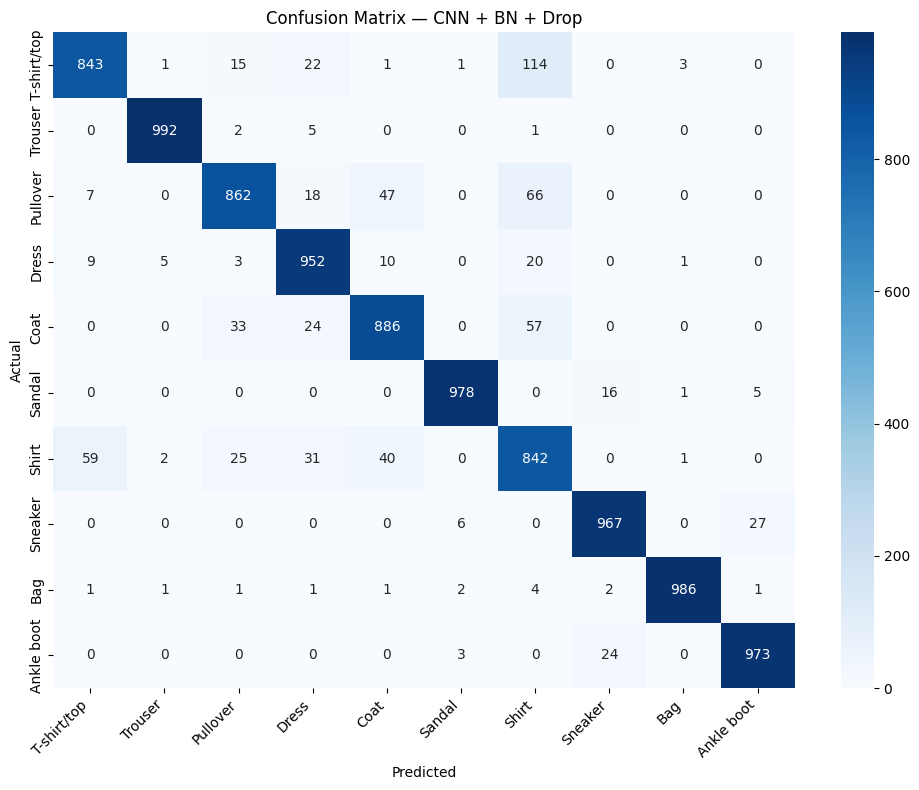

In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_true, best_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=list(class_names.values()),
            yticklabels=list(class_names.values()))
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

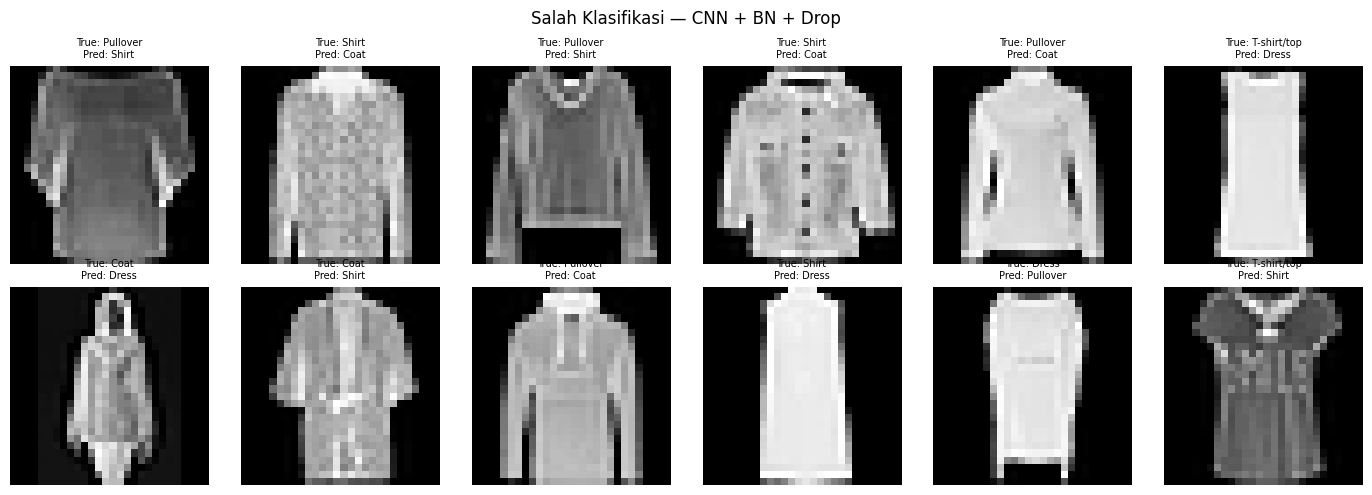

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

best_model = [ann, cnn, cnn_bn][best_idx]

wrong_mask = best_preds != y_true
wrong_X    = X_test_raw[wrong_mask][:12]
wrong_true = y_true[wrong_mask][:12]
wrong_pred = best_preds[wrong_mask][:12]

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(wrong_X[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"True: {class_names[wrong_true[i]]}\nPred: {class_names[wrong_pred[i]]}", fontsize=7)
    ax.axis("off")
plt.suptitle(f"Salah Klasifikasi — {best_name}")
plt.tight_layout(); plt.show()

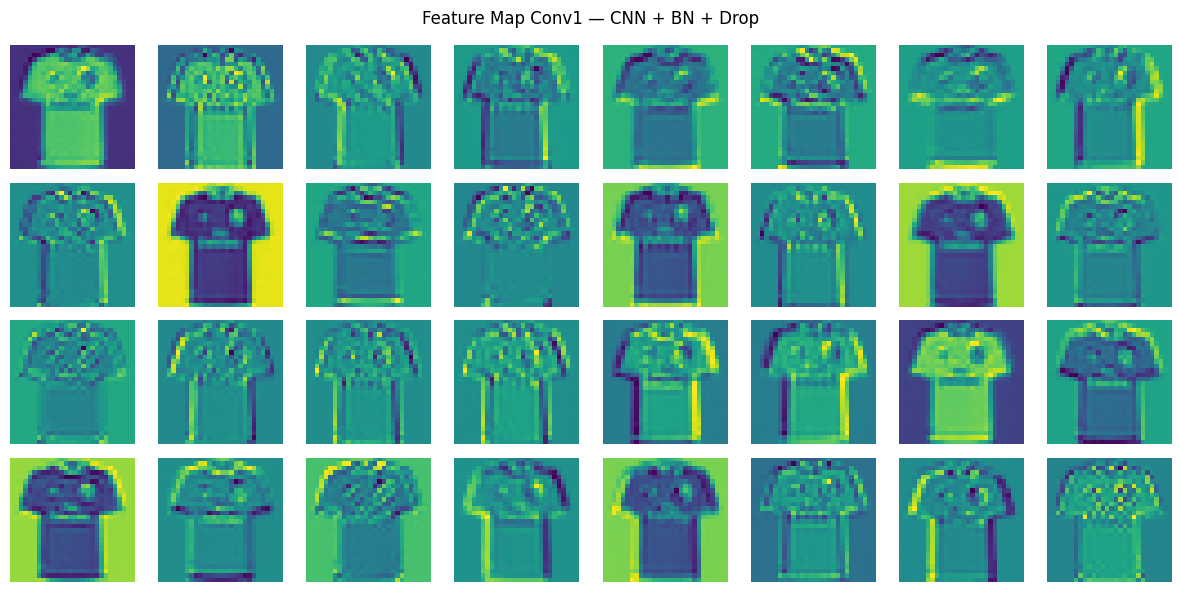

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

sample_x = torch.tensor(X_test_raw[0], dtype=torch.float32).reshape(1, 1, 28, 28).to(device)

best_model.eval()
with torch.no_grad():
    fmap = best_model.features[0](sample_x)  # output (1, 32, 28, 28)

fmap_np = fmap.squeeze(0).cpu().numpy()  # (32, 28, 28)
n_filters = fmap_np.shape[0]

cols = 8
rows = (n_filters + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5))
for i, ax in enumerate(axes.flat):
    if i < n_filters:
        ax.imshow(fmap_np[i], cmap="viridis")
    ax.axis("off")
plt.suptitle(f"Feature Map Conv1 — {best_name}")
plt.tight_layout(); plt.show()

In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

torch.save(best_model.state_dict(), "model.pth")
print(f"Model '{best_name}' disimpan ke model.pth")
# shortcut: definisi class tidak disimpan ke file terpisah, perlu copy-paste class saat deployment

Model 'CNN + BN + Drop' disimpan ke model.pth


# 5. Analisis

### 5.1 Perbandingan Performa Model

Berdasarkan hasil eksperimen pengujian pada data uji (Test Set sebanyak 10.000 sampel), diperoleh ringkasan evaluasi sebagai berikut:

| Model | Parameter | Test Accuracy | Precision (Macro) | Recall (Macro) | F1-Score (Macro) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **ANN (Baseline)** | 235,146 | 0.9000 | 0.9006 | 0.9000 | 0.8999 |
| **CNN Sederhana** | 421,642 | 0.9234 | 0.9241 | 0.9234 | 0.9235 |
| **CNN + BatchNorm + Dropout** | 421,834 | **0.9281** | **0.9298** | **0.9281** | **0.9284** |

1. **ANN vs CNN**:
   - Model ANN bekerja dengan meratakan (*flatten*) gambar 28×28 menjadi vektor 784 dimensi sejak awal. Pendekatan ini menghilangkan informasi relasi spasial antar piksel yang bersebelahan. Akibatnya, performa ANN mentok di akurasi 90.00%.
   - Model CNN mempertahankan matriks 2D spasial menggunakan kernel konvolusi 3×3, sehingga mampu mengekstraksi fitur visual lokal (garis tepi, tekstur, lekukan pakaian) secara hierarkis (translation invariance). Hal ini terbukti meningkatkan akurasi menjadi 92.34% pada CNN Sederhana.

2. **Pengaruh Parameter**:
   - CNN memiliki parameter yang lebih besar (421k vs 235k) terutama akibat layer `Linear(64*7*7, 128)` setelah proses perataan feature map. Peningkatan parameter ini terbukti efektif dan sebanding dengan peningkatan generalisasi performa model.

3. **Pengaruh Batch Normalization dan Dropout**:
   - Penambahan Batch Normalization menstabilkan distribusi input antar-layer (*internal covariate shift*), mempercepat proses konvergensi loss saat training, dan bertindak sebagai regularizer ringan.
   - Penambahan Dropout (p=0.5) sebelum output layer mencegah ketergantungan co-adaptasi antar-neuron.
   - Pada learning curve, model CNN sederhana menunjukkan gejala overfitting ringan di mana validation loss mulai stagnan/naik perlahan setelah epoch ke-8, sementara pada model CNN + BN + Dropout jarak antara kurva train dan val jauh lebih rapat dan stabil, menghasilkan akurasi tertinggi sebesar 92.81%.

---

### 5.2 Analisis Kesalahan dan Pasangan Kelas yang Tertukar

Berdasarkan Confusion Matrix dan Classification Report model terbaik (CNN + BN + Dropout):
1. **Kelas Paling Akurat**:
   - Kelas **Trouser** (F1: 0.99), **Bag** (F1: 0.99), dan **Sandal** (F1: 0.98) memiliki akurasi klasifikasi hampir sempurna karena memiliki bentuk geometri dan proporsi kontur piksel yang sangat unik dan berbeda dari kategori pakaian atasan.
2. **Kelas Paling Sulit & Sering Tertukar**:
   - Kelas **Shirt** memiliki F1-score terendah (0.80) dengan Precision 0.76.
   - Pasangan kelas yang paling banyak tertukar adalah **Shirt vs T-shirt/top** dan **Shirt vs Pullover / Coat**.
   - Hal ini wajar secara visual karena pada resolusi rendah (28×28 piksel grayscale), detail pembeda seperti kerah kemeja, kancing depan, atau jahitan bahu kabur dan sangat menyerupai kaos (T-shirt) maupun sweater tipis.

---

### 5.3 Analisis Feature Map Layer Konvolusi Pertama

Visualisasi 32 channel feature map pada Conv1 menunjukkan:
- Filter-filter awal fokus mendeteksi fitur tingkat rendah (*low-level features*), seperti tepi vertikal/horizontal (*edge detection*), batas siluet pakaian terhadap background gelap, serta gradien intensitas cahaya pada area tengah kain.

# 6. Kesimpulan dan Saran

### 6.1 Kesimpulan
1. Arsitektur Convolutional Neural Network (CNN) terbukti jauh lebih unggul dibandingkan Artificial Neural Network (ANN) untuk klasifikasi gambar pakaian Fashion-MNIST, karena mampu mempertahankan korelasi spasial lokal piksel.
2. Model terbaik dicapai oleh arsitektur **CNN dengan Batch Normalization dan Dropout** dengan akurasi pengujian sebesar **92.81%** dan F1-Score sebesar **0.9284**, mengungguli CNN standar (92.34%) dan ANN baseline (90.00%).
3. Regularisasi menggunakan Dropout dan Batch Normalization terbukti efektif menekan overfitting dan menjaga stabilitas learning curve antara data latih dan validasi.
4. Tantangan utama klasifikasi terletak pada kelompok pakaian atasan (*tops/outerwear*), khususnya pembedaan antara `Shirt`, `T-shirt/top`, dan `Pullover` akibat resolusi gambar yang rendah (28×28).

---

### 6.2 Saran
1. **Penerapan Data Augmentation**: Melakukan augmentasi data ringan seperti `RandomHorizontalFlip` dan `RandomCrop` untuk memperkaya variasi sampel pakaian atasan agar model lebih tahan terhadap variasi posisi dan bentuk.
2. **Eksplorasi Arsitektur yang Lebih Dalam**: Menambah blok konvolusi (misal 3-4 layer) atau memanfaatkan arsitektur modern seperti residual connections (ResNet mini) guna mengekstraksi fitur visual yang lebih kompleks.
3. **Optimasi Hyperparameter**: Menggunakan Learning Rate Scheduler (seperti `CosineAnnealingLR` atau `ReduceLROnPlateau`) dan fine-tuning tingkat dropout (misal 0.3 atau 0.4) untuk memaksimalkan akurasi tanpa memicu underfitting.